# Notebook 2: How do we know if things get better?

Leadership wants "open tickets" to go down. In this notebook we show why that number alone is not a
good target, and we pick better numbers to watch every week.

## Step 1: Load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Read the ticket file
df = pd.read_csv("../backend/data/rideops_support_tickets.csv")

# Turn the date columns into real dates
for col in ["created_at", "first_response_at", "first_closed_at", "final_closed_at"]:
    df[col] = pd.to_datetime(df[col])

# The data was pulled at the end of 30 Sep 2026. We treat that as "now".
now = pd.Timestamp("2026-09-30 23:59")

# Simple yes / no columns
df["escalated"] = df["escalated_to_eng"] == "Yes"
df["is_open"] = df["status"] != "Closed"
df["reopened"] = df["reopen_count"] > 0

# "Bounced" = sent to engineering, but engineering did not fix it
df["eng_outcome"] = df["eng_outcome"].fillna("")
df["bounced"] = df["escalated"] & (df["eng_outcome"] != "Fixed")

# Hours from created to closed (empty if the ticket is still open)
df["hours_to_close"] = (df["final_closed_at"] - df["created_at"]).dt.total_seconds() / 3600

# Same, but open tickets are counted up to "now"
end_time = df["final_closed_at"].fillna(now)
df["age_hours"] = (end_time - df["created_at"]).dt.total_seconds() / 3600

# Replace numbers with N, so similar problems get the same name
df["issue_type"] = df["description"].str.replace(r"\d+", "N", regex=True)

print("Tickets:", len(df))

Tickets: 1444


## Step 2: Look closely at the open tickets

Not every open ticket is a problem. A ticket raised one hour ago is open, and that is normal.

In [2]:
open_now = df[df["is_open"]]
old_open = open_now[open_now["age_hours"] >= 48]
new_open = open_now[open_now["age_hours"] < 48]

print("Open tickets now:", len(open_now))
print("Open for more than 48 hours:", len(old_open))
print("Open for less than 48 hours:", len(new_open))
print()
print("Of the old ones, how many went to engineering:", (old_open["eng_handoffs"] > 0).sum())

Open tickets now: 48
Open for more than 48 hours: 25
Open for less than 48 hours: 23

Of the old ones, how many went to engineering: 24


**What we see**

- 48 tickets are open. 25 are older than 48 hours, and 23 are new.
- 24 of the 25 old ones have been to engineering.

The new ones are normal work. The old ones are the real problem, so we should count those.

There is a second reason. "Open tickets" can be lowered by closing tickets too early. Notebook 1
showed one agent already does this.

## Step 3: Is 48 hours a fair line?

We check how long normal tickets take.

In [3]:
support_only = df[~df["escalated"]]["hours_to_close"].dropna()
with_engineering = df[df["escalated"]]["hours_to_close"].dropna()

print("Tickets solved by support alone:")
print("  half are closed within", round(support_only.median(), 1), "hours")
print("  closed within 48 hours:", round((support_only <= 48).mean() * 100), "%")
print()
print("Tickets sent to engineering:")
print("  closed within 48 hours:", round((with_engineering <= 48).mean() * 100), "%")

Tickets solved by support alone:
  half are closed within 12.6 hours
  closed within 48 hours: 92 %

Tickets sent to engineering:
  closed within 48 hours: 20 %


**What we see**

92% of normal tickets close within 48 hours, but only 20% of engineering tickets do. So "older than
48 hours" is a fair sign that a ticket is stuck.

## Step 4: The numbers to watch

| Type | Number | Today | Why |
|---|---|---|---|
| **Main number** | Open tickets older than 48 hours | 25 | This is what clients feel |
| Cause | % of engineering tickets that come back | 57% | The root of the problem |
| Cause | Tickets with 2 or more trips to engineering | 229 in 3 months | Each trip costs about two days |
| **Safety check** | % of tickets reopened by clients | 10.5% | Must not go up, or we are just closing early |
| **Safety check** | Average client rating | 3.70 | Must not go down |

The two safety checks stop us from "improving" the main number in a bad way.

## Step 5: These numbers, week by week

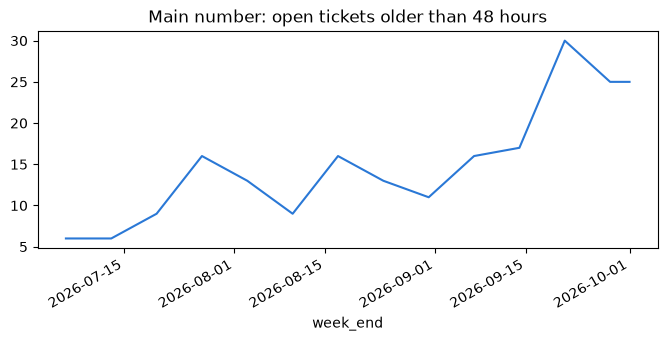

In [4]:
# For each Monday, count the tickets that were open at that moment
week_ends = list(pd.date_range("2026-07-06", "2026-09-28", freq="7D")) + [now]

rows = []
for day in week_ends:
    created_before = df["created_at"] < day
    not_closed_yet = df["final_closed_at"].isna() | (df["final_closed_at"] >= day)
    open_then = df[created_before & not_closed_yet]

    hours_open = (day - open_then["created_at"]).dt.total_seconds() / 3600
    older_than_48h = open_then[hours_open >= 48]

    rows.append({"week_end": day, "open": len(open_then), "open_over_48h": len(older_than_48h)})

backlog = pd.DataFrame(rows)

backlog.plot(x="week_end", y="open_over_48h", color="#2a78d6", legend=False,
             title="Main number: open tickets older than 48 hours", figsize=(8, 3.2))
plt.show()

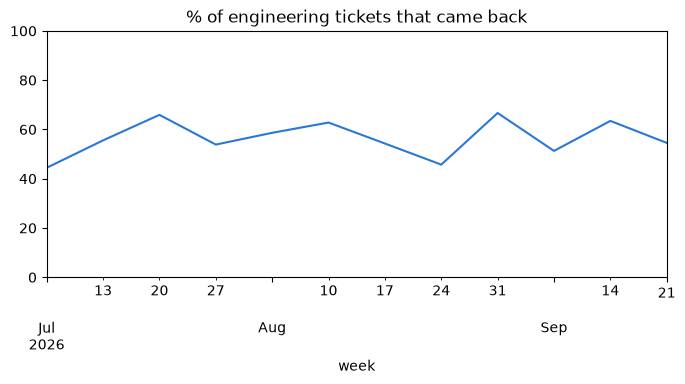

,new_tickets,two_or_more_trips,reopened_rate,average_rating,came_back_rate
week,,,,,
2026-07-06,87,10,0.13,3.73,0.44
2026-07-13,87,12,0.07,3.86,0.56
2026-07-20,97,27,0.05,3.68,0.66
2026-07-27,88,16,0.17,3.44,0.54
2026-08-03,107,13,0.11,3.86,0.59
2026-08-10,103,25,0.09,3.63,0.63
2026-08-17,117,17,0.10,3.95,0.54
2026-08-24,114,13,0.06,3.66,0.46
2026-08-31,105,18,0.15,3.46,0.67


In [5]:
# Put each ticket in the week it was raised (weeks start on Monday)
df["week"] = df["created_at"].dt.to_period("W").dt.start_time

df["two_or_more_trips"] = df["eng_handoffs"] >= 2

weekly = df.groupby("week").agg(
    new_tickets=("ticket_id", "count"),
    two_or_more_trips=("two_or_more_trips", "sum"),
    reopened_rate=("reopened", "mean"),
    average_rating=("csat_score", "mean"),
)
weekly["came_back_rate"] = df[df["escalated"]].groupby("week")["bounced"].mean()

# The first and last weeks are not full weeks, so we leave them out
weekly = weekly.iloc[1:-1]

(weekly["came_back_rate"] * 100).plot(color="#2a78d6", figsize=(8, 3.2),
                                      title="% of engineering tickets that came back")
plt.ylim(0, 100)
plt.show()
weekly.round(2)

**What we see**

- The main number goes up through the three months, like the complaint says.
- The "came back" rate is high in every single week. It did not get worse. It was always bad.

So the process was always leaky. When more tickets arrived, the same leak made a bigger pile.

## Step 6: Where we are today

In [6]:
sent_to_eng = df[df["escalated"]]

print("Open tickets older than 48 hours:", len(old_open))
print("Engineering tickets that came back:", round(sent_to_eng["bounced"].mean() * 100, 1), "%")
print("Tickets with 2+ trips, per week:", round(weekly["two_or_more_trips"].mean(), 1))
print("Tickets reopened by clients:", round(df["reopened"].mean() * 100, 1), "%")
print("Average client rating:", round(df["csat_score"].mean(), 2))

Open tickets older than 48 hours: 25
Engineering tickets that came back: 56.6 %
Tickets with 2+ trips, per week: 18.0
Tickets reopened by clients: 10.5 %
Average client rating: 3.7


## Step 7: Targets for the next four weeks

These targets are my suggestion. The data gives us today's numbers. The targets are what we would
see if the check stops **half** of the returns it can stop (see notebook 3). They are something to
agree with the team, not a promise.

| Number | Today | Target | Why |
|---|---|---|---|
| Open tickets older than 48 hours | 25 | about 18 | Notebook 3 gives 18.5 if half are stopped |
| Engineering tickets that come back | 57% | under 40% | The same case gives about 38% |
| Tickets with 2+ trips, per week | about 18 | about 11 | Most multi-trip tickets are returns the check can stop |
| Tickets reopened | 10.5% | not higher | Safety check |
| Client rating | 3.70 | not lower | Safety check |

In [7]:
# Where the targets come from: what if the check stops half of the returns it can stop?
support_can_solve = sent_to_eng["eng_outcome"].isin(["Config issue - returned to L1", "Not a bug - how-to"])
one_clean_trip = sent_to_eng["eng_outcome"].isin(["Insufficient info - returned to L1", "Not reproducible"])
can_stop = support_can_solve | one_clean_trip

# Tickets support solves are no longer sent to engineering at all
still_sent = len(sent_to_eng) - 0.5 * support_can_solve.sum()
still_come_back = sent_to_eng["bounced"].sum() - 0.5 * can_stop.sum()
print("Came back rate if half are stopped:", round(still_come_back / still_sent * 100), "%")

multi_trip = sent_to_eng[sent_to_eng["eng_handoffs"] >= 2]
can_stop_multi = can_stop[multi_trip.index].sum()
print("Multi-trip tickets:", len(multi_trip), "- of these the check can stop:", can_stop_multi)
per_week_now = weekly["two_or_more_trips"].mean()
print("2+ trip tickets per week if half are stopped:",
      round(per_week_now * (1 - 0.5 * can_stop_multi / len(multi_trip)), 1))

Came back rate if half are stopped: 38 %
Multi-trip tickets: 229 - of these the check can stop: 179
2+ trip tickets per week if half are stopped: 11.0
